# 02 · Herramientas: el agente deja de inventar

En el módulo anterior vimos que la forma se impone por el **canal de herramientas**, pero
sin explicar qué es una herramienta. Vamos a ello.

Una **herramienta** es una función de Python con dos añadidos que el modelo puede leer:

* un **nombre**,
* un **docstring**, que hace de descripción para el modelo.

Y nada más. El modelo no ejecuta nada: **pide** que se ejecute, y el grafo lo ejecuta.
Esta separación es la idea central del módulo:

> El modelo **decide**. El grafo **ejecuta**. Tú **controlas qué puede decidir**.

## 2.1 Definir herramientas y ver lo que ve el modelo

El decorador `@tool` construye el esquema a partir de la firma y del docstring. Merece la
pena mirar ese esquema: es literalmente el texto que el modelo recibe para decidir si
usa la herramienta.

In [1]:
import json
from langchain.tools import tool

@tool
def buscar_precio(producto: str) -> float:
    """Devuelve el precio estimado de un producto en EUR. Productos disponibles: pollo, arroz, espinacas."""
    precios = {"pollo": 5.0, "arroz": 2.0, "espinacas": 3.0}
    return precios.get(producto.lower(), 9.99)

@tool
def convertir_moneda(cantidad: float, origen: str, destino: str) -> float:
    """Convierte una cantidad de dinero entre EUR y USD."""
    tasas = {("EUR", "USD"): 1.10, ("USD", "EUR"): 0.90}
    return round(cantidad * tasas.get((origen.upper(), destino.upper()), 1.0), 2)

HERRAMIENTAS = [buscar_precio, convertir_moneda]

print("Estas herramientas son objetos Python normales. Puedo llamarlas yo mismo:")
print("  buscar_precio ->", buscar_precio.invoke({"producto": "pollo"}))
print()
print("Y este es el contrato que recibe el modelo:")
print(json.dumps(buscar_precio.tool_call_schema.model_json_schema(), ensure_ascii=False, indent=2))


Estas herramientas son objetos Python normales. Puedo llamarlas yo mismo:
  buscar_precio -> 5.0

Y este es el contrato que recibe el modelo:
{
  "description": "Devuelve el precio estimado de un producto en EUR. Productos disponibles: pollo, arroz, espinacas.",
  "properties": {
    "producto": {
      "title": "Producto",
      "type": "string"
    }
  },
  "required": [
    "producto"
  ],
  "title": "buscar_precio",
  "type": "object"
}


Ese JSON es todo lo que el modelo sabe de nuestra función. De ahí se deduce una regla
práctica: **un docstring vago hace una herramienta inservible**. Si no describes bien
cuándo usarla, el modelo no la usará, o la usará mal.

## 2.2 El bucle ReAct, escrito a mano

Ahora montamos el ciclo completo. Es un grafo con dos nodos:

```
START -> agente -> (¿pidió herramientas?) -> herramientas -> agente -> ... -> END
```

* **`agente`**: le pregunta al modelo qué hacer. Si quiere una herramienta, lo dice.
* **`herramientas`**: ejecuta lo que pidió y le devuelve el resultado.

La arista del medio es **condicional**: es la decisión de si el agente sigue trabajando
o ya ha terminado. Ahí está toda la «inteligencia» del bucle.

**Un detalle que hace perder veinte minutos si no lo sabes:** `tools_condition` devuelve
por defecto los literales `"tools"` y `"__end__"`. Si tu nodo se llama de otra forma
—como aquí, `herramientas`— hay que **mapear** la salida. LangGraph no adivina por
parecido de nombres. Eso es exactamente lo que hace el tercer argumento de
`add_conditional_edges`.

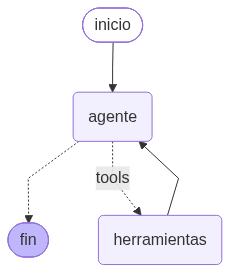

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	agente(agente)
	herramientas(herramientas)
	__end__([fin]):::last
	__start__ --> agente;
	agente -.-> __end__;
	agente -. tools .-> herramientas;
	herramientas --> agente;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 2: el bucle ReAct  ·  guardado en grafos/grafo-2-el-bucle-react.mmd


In [2]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
import comun

modelo = comun.llm()
modelo_con_herramientas = modelo.bind_tools(HERRAMIENTAS)

def nodo_agente(estado: MessagesState):
    """El modelo decide qué hacer con la conversación."""
    return {"messages": [modelo_con_herramientas.invoke(estado["messages"])]}

constructor = StateGraph(MessagesState)
constructor.add_node("agente", nodo_agente)
constructor.add_node("herramientas", ToolNode(HERRAMIENTAS))
constructor.add_edge(START, "agente")

# La arista condicional. El mapa traduce la salida de tools_condition
# ("tools" / "__end__") al nombre real de nuestro nodo.
constructor.add_conditional_edges(
    "agente", tools_condition, {"tools": "herramientas", "__end__": END}
)

constructor.add_edge("herramientas", "agente")   # <- aquí está el bucle
agente_manual = constructor.compile()

comun.ver_grafo(agente_manual, "Grafo 2: el bucle ReAct")


Fíjate en la flecha que vuelve de `herramientas` a `agente`. **Esa flecha es el bucle.**
En un framework de cadenas esto está escondido dentro de un `AgentExecutor`; aquí lo
estás viendo dibujado, y si quisieras poner un límite de iteraciones o un humano de por
medio, sabrías exactamente dónde pincharlo.

## 2.3 Ejecutarlo y, sobre todo, **leer la traza**

Lo importante no es que responda bien, sino **ver cómo lo ha hecho**. La lista de
mensajes del estado es la caja de cristal del agente:

| Tipo de mensaje | Quién lo emite | Qué significa |
|---|---|---|
| `HumanMessage` | tú | la petición |
| `AIMessage` con `tool_calls` | el modelo | «quiero ejecutar esto» |
| `ToolMessage` | tu código | el resultado de la herramienta |
| `AIMessage` final | el modelo | la respuesta ya con los datos reales |

Si no ves `tool_calls`, el modelo **se lo está inventando**. Ese es el síntoma exacto
que hay que saber detectar.

In [3]:
import comun

entrada = "¿Cuánto cuesta el pollo? ¿Y cuánto son 100 EUR en USD?"
resultado = agente_manual.invoke({"messages": [{"role": "user", "content": entrada}]})

print("PREGUNTA:", entrada)
print()
comun.ver_mensajes(resultado)
print()
print("RESPUESTA FINAL:")
print(resultado["messages"][-1].content[:300])


PREGUNTA: ¿Cuánto cuesta el pollo? ¿Y cuánto son 100 EUR en USD?

[00] HumanMessage                 ¿Cuánto cuesta el pollo? ¿Y cuánto son 100 EUR en USD?
[01] AIMessage  ->  TOOL_CALLS: buscar_precio({'producto': 'pollo'}), convertir_moneda({'cantidad': 100, 'destino': 'USD', 'origen': 'EUR'}) 
[02] ToolMessage                  5.0
[03] ToolMessage                  110.0
[04] AIMessage                    El pollo cuesta 5.0 EUR y 100 EUR equivalen a 110.0 USD.

RESPUESTA FINAL:
El pollo cuesta 5.0 EUR y 100 EUR equivalen a 110.0 USD.


Lee la traza en voz alta conmigo, porque es el corazón del módulo:

1. `[00] HumanMessage` — la pregunta.
2. `[01] AIMessage -> TOOL_CALLS: buscar_precio(...), convertir_moneda(...)` — el modelo
   **no contesta**: pide dos herramientas. Y las pide **a la vez**, en paralelo.
3. `[02]` y `[03] ToolMessage` — los resultados reales: `5.0` y `110.0`.
   Esos números no los ha inventado el modelo: los ha calculado Python.
4. `[04] AIMessage` — ahora sí responde, con los datos que le hemos dado.

Esa es la diferencia entre un chatbot que opina y un agente que consulta.

## 2.4 Cuando una herramienta falla

Las herramientas son código, y el código falla. Una división por cero, una API caída, un
producto que no existe. Si el error se propaga, el agente se cae entero.

`ToolNode` puede convertir la excepción en un `ToolMessage` de error, de modo que el
modelo **se entere y se recupere**. Compara las dos situaciones.

In [4]:
from langchain.tools import tool

@tool
def dividir(a: float, b: float) -> float:
    """Divide el número a entre el número b."""
    return a / b

# 1) La herramienta, invocada directamente: el error sale disparado.
try:
    dividir.invoke({"a": 6, "b": 0})
except Exception as error:
    print(f"Sin protección -> {type(error).__name__}: {error}")


Sin protección -> ZeroDivisionError: float division by zero


In [5]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.messages import SystemMessage
import comun

# 2) El mismo fallo, pero dentro de un grafo que sí maneja el error.
modelo_div = modelo.bind_tools([dividir])

def nodo_div(estado: MessagesState):
    sistema = SystemMessage(content=(
        "Usa la herramienta dividir. Si la herramienta falla, "
        "explica el error al usuario en una frase."
    ))
    return {"messages": [modelo_div.invoke([sistema] + estado["messages"])]}

c = StateGraph(MessagesState)
c.add_node("agente", nodo_div)
c.add_node("herramientas", ToolNode([dividir], handle_tool_errors=True))
c.add_edge(START, "agente")
c.add_conditional_edges("agente", tools_condition, {"tools": "herramientas", "__end__": END})
c.add_edge("herramientas", "agente")
grafo_div = c.compile()

salida = grafo_div.invoke({"messages": [{"role": "user", "content": "Divide 6 entre 0."}]})
comun.ver_mensajes(salida)
print()
print("RESPUESTA FINAL:")
print(salida["messages"][-1].content[:300])


[00] HumanMessage                 Divide 6 entre 0.
[01] AIMessage  ->  TOOL_CALLS: dividir({'a': 6, 'b': 0}) 
[02] ToolMessage                  Error: ZeroDivisionError('float division by zero')  Please fix your mistakes.
[03] AIMessage                    Se ha producido un error porque no es posible dividir un número entre cero.

RESPUESTA FINAL:
Se ha producido un error porque no es posible dividir un número entre cero.


Fíjate en la `ToolMessage`: contiene **el texto del error**, no una excepción. Eso es
`handle_tool_errors=True` en acción. La consecuencia práctica es enorme: el agente puede
**leer** que su herramienta ha fallado y reaccionar —pedir otro dato, disculparse,
proponer una alternativa— en lugar de morir con un `Traceback`.

La lección de diseño: los errores de tus herramientas son **información para el agente**,
no solo un problema para tu `try/except`.

## 2.5 Todo esto, en una línea: `create_agent`

Acabamos de escribir a mano el bucle que implementan todos los agentes. Ahora la pregunta
honesta: ¿para qué tanto trabajo si existe un atajo?

Porque **ahora sabes qué hace el atajo por dentro**. Y eso importa el día que el agente se
comporte raro: sabrás si mirar el prompt, la arista condicional o el manejo de errores.

`create_agent` construye exactamente el mismo grafo que hemos montado nosotros.

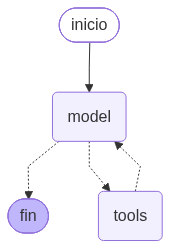

---
config:
 flowchart:
  curve: linear
---
graph TD;
	__start__([inicio]):::first
	model(model)
	tools(tools)
	__end__([fin]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


[grafo] Grafo 2b: lo que construye create_agent por dentro  ·  guardado en grafos/grafo-2b-lo-que-construye-create-agent-por-dentro.mmd


In [6]:
from langchain.agents import create_agent

agente_atajo = create_agent(
    modelo,
    tools=HERRAMIENTAS,
    system_prompt="Eres un chef conciso. Usa las herramientas cuando necesites datos.",
)

comun.ver_grafo(agente_atajo, "Grafo 2b: lo que construye create_agent por dentro")


In [7]:
resultado = agente_atajo.invoke(
    {"messages": [{"role": "user", "content": "¿Cuánto cuesta el arroz y a cuánto van 50 USD?"}]}
)
comun.ver_mensajes(resultado)
print()
print("RESPUESTA:", resultado["messages"][-1].content[:300])


[00] HumanMessage                 ¿Cuánto cuesta el arroz y a cuánto van 50 USD?
[01] AIMessage  ->  TOOL_CALLS: buscar_precio({'producto': 'arroz'}), convertir_moneda({'cantidad': 50, 'destino': 'EUR', 'origen': 'USD'}) 
[02] ToolMessage                  2.0
[03] ToolMessage                  45.0
[04] AIMessage                    El arroz cuesta 2.00 € y 50 USD equivalen a 45.00 €.

RESPUESTA: El arroz cuesta 2.00 € y 50 USD equivalen a 45.00 €.


Ese grafo tiene más nodos que el nuestro (gestión de errores de herramientas, de modelo,
etc.), pero la estructura es la misma que has construido a mano. **Ya no es una caja negra.**

---

## Resumen del módulo

| Idea | Detalle |
|---|---|
| Una herramienta es una función + nombre + docstring | El docstring es el prompt de la herramienta |
| El modelo **no ejecuta**: pide | `AIMessage.tool_calls` es la petición |
| El grafo ejecuta y devuelve `ToolMessage` | Ahí llegan los datos reales |
| La arista condicional es el bucle | `tools_condition` decide seguir o parar |
| `tools_condition` devuelve `"tools"` / `"__end__"` | Si tu nodo se llama distinto, **mapea** |
| Sin `tool_calls` en la traza, el modelo se lo inventó | Es el síntoma a detectar |
| `handle_tool_errors=True` convierte el fallo en observación | El agente se recupera solo |
| `create_agent` hace lo mismo en una línea | Pero ahora sabes qué hay dentro |

## Ejercicios

1. **Herramienta que miente.** Haz que `buscar_precio` devuelva siempre `0.01`. ¿Se da
   cuenta el agente de que el precio es absurdo? Comenta el resultado: el agente confía
   en sus herramientas, y eso es una responsabilidad tuya, no del modelo.

2. **Docstring vago.** Cambia el docstring de `buscar_precio` por `"Busca cosas."` y repite
   la pregunta del apartado 2.3. ¿Sigue usándola correctamente? Escribe la diferencia.

3. **Tres herramientas en paralelo.** Añade `contar_calorias(ingrediente)`. Pregunta por
   precio, moneda y calorías en la misma frase. ¿Cuántos `TOOL_CALLS` ves en un solo
   `AIMessage`?

4. **Una herramienta que siempre falla.** Añade una que lance `ValueError("servicio caído")`
   y pregunta algo que la requiera. Describe cómo reacciona el modelo con
   `handle_tool_errors=True` y qué pasa con `handle_tool_errors=False`.

5. **Poner un límite.** Un bucle ReAct puede girar indefinidamente. Busca
   `recursion_limit` en la documentación de LangGraph y limita el grafo a 4 pasos.
   ¿Qué excepción lanza al pasarse?

6. **Tu propia herramienta.** Escribe una que consulte algo real (la hora del sistema, una
   API pública, un fichero local). Cuida el docstring: es lo único que el modelo verá.